# Notebook 01 -- Model Demonstration (M1)

This notebook is the M1 deliverable from
[`../../cstr_sbi_execution_plan.md`](../../cstr_sbi_execution_plan.md):
the closed-loop CSTR ODE with a PI controller, anti-windup, and the two
multiplicative degradation factors (alpha for catalyst decay, beta for
jacket fouling), all running on the JAX/diffrax stack.

We will walk through:

1. **Open-loop dynamics** -- the 3-state ODE with fixed `Qc` (Scenario 0).
2. **Closed-loop dynamics, healthy reactor** -- the 4-state ODE with PI
   integrator (Scenario 1, alpha = beta = 1).
3. **The headline phenomenon** -- jacket fouling masks itself in `T`
   while the controller compensates by changing `Qc`; catalyst decay leaves a
   qualitatively different signature in `Qc`.
4. **Controller saturation** -- the regime where `Qc` hits its valve limit
   and `T` is no longer regulated (Scenario 5).

Physical and controller constants are in `cstr_sbi.physics`
(Fogler 2016 Module 13 / Furusawa 1969 chemistry, propylene-oxide hydrolysis; k0 modified, see below).


> **Parameter note (2026-11-08).** All constants are Fogler 2016 / Furusawa 1969 values
> **except the pre-exponential factor**: `K0_NOMINAL = 1.696×10¹³ min⁻¹` is Fogler's number
> with the unit read as min⁻¹ instead of h⁻¹, i.e. 60× Fogler's rate constant (notebook 25).
> It is kept deliberately (a high-conversion design, ~98% conversion) and must be disclosed as
> a modification; see `docs/Manuscript/system_i_study_parameter_rationale.md`. The documents
> `cstr_parameters_recommended.md`, `cstr_sbi_execution_plan.md` and `cstr_sbi_research_spec.md`
> referenced below are not in this repository.
>
> **Controller-form fix (2026-11-08).** The PI law is now the standard, dimensionally
> consistent form `Qc = Qc0 + Kp·[(T − Tsp) + I/τi]`. The previous code added `I/τi` without
> `Kp`, which made the integral action 150× too weak (closed-loop slow mode of 1,600–5,500 min
> instead of 10–26 min). This notebook's earlier text explained the slow convergence as a
> property of the tuning; it was the bug. Trajectories are now run for 300 min instead of
> 2000 min, and the scenario values follow the current catalogue (Sc2 β = 0.85). Outputs below
> were cleared and must be regenerated.

## 1. Setup and constants

The package exposes the nominal operating point as module-level arrays
so that every notebook and script uses the same numbers.


In [11]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cstr_sbi.physics import (
    NOMINAL_INLET, NOMINAL_PARAMS, NOMINAL_Y0,
    NOMINAL_INLET_CL, NOMINAL_PARAMS_CL, NOMINAL_CTRL, NOMINAL_Y0_CL,
    UA_NOMINAL, K0_NOMINAL,
    KP, TAU_I, TSP, QC0, QC_MIN, QC_MAX,
    V, V_C, Q,
    cstr_open_loop_rhs,
    simulate_open_loop_to_steady_state,
    simulate_closed_loop_to_steady_state,
    simulate_closed_loop_trajectory,
    compute_qc,
)

print("JAX devices:", jax.devices())
print()
print("PI controller:")
print(f"  Tsp = {TSP} K     Kp = {KP:>+8.2f} (L/min)/K     tau_i = {TAU_I} min")
print(f"  Qc bias = {QC0} L/min     Qc range = [{QC_MIN}, {QC_MAX}] L/min")
print()
print(f"Reactor:  V = {V} L,   V_c = {V_C} L,   Q = {Q} L/min  ->  tau = V/Q = {V/Q} min")
print(f"Nominal params (UA, k0): {np.asarray(NOMINAL_PARAMS)}")

JAX devices: [CpuDevice(id=0)]

PI controller:
  Tsp = 312.5 K     Kp =  +150.00 (L/min)/K     tau_i = 10.0 min
  Qc bias = 80.0 L/min     Qc range = [0.0, 400.0] L/min

Reactor:  V = 500.0 L,   V_c = 40.0 L,   Q = 40.0 L/min  ->  tau = V/Q = 12.5 min
Nominal params (UA, k0): [1.250e+04 1.696e+13]


## 2. Open-loop dynamics (Scenario 0)

In open-loop, `Qc` is a fixed input. We start from the warm IC
`[C=0.5, T=300, Tc=297]` and let the system relax to its asymptote.
The trajectory shows the characteristic exponential approach to a
steady state set by the energy balance with feed cooling and a fixed
jacket flow.


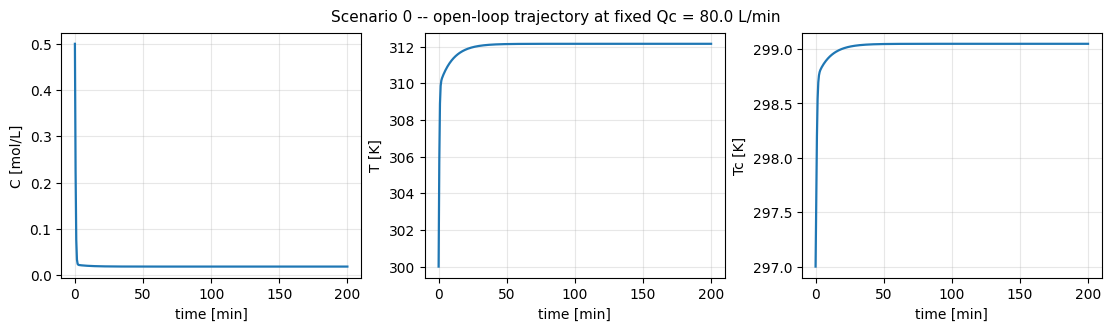

Open-loop steady state at Qc = 80.0 L/min:
  C = 0.01835 mol/L,  T = 312.1483 K,  Tc = 299.0471 K


In [12]:
from cstr_sbi.physics import (
    E_A, R_GAS, H_R, RHO, RHO_C, C_P, C_PC,
)
from scipy.integrate import solve_ivp

def open_loop_traj(Qc_value, t_final=200.0, n_save=401):
    """Pure-numpy open-loop CSTR ODE -- avoids per-step JAX tracing."""
    Ci, Ti, Tci = float(NOMINAL_INLET[0]), float(NOMINAL_INLET[1]), float(NOMINAL_INLET[2])
    UA, k0 = float(NOMINAL_PARAMS[0]), float(NOMINAL_PARAMS[1])
    def rhs(t, y):
        C, T, Tc = y
        k = k0 * np.exp(-E_A / (R_GAS * T))
        return [
            (Q / V) * (Ci - C) - k * C,
            (Q / V) * (Ti - T) - H_R * k * C / (RHO * C_P) - UA * (T - Tc) / (RHO * C_P * V),
            (Qc_value / V_C) * (Tci - Tc) + UA * (T - Tc) / (RHO_C * C_PC * V_C),
        ]
    sol = solve_ivp(
        rhs, (0.0, t_final), np.asarray(NOMINAL_Y0),
        t_eval=np.linspace(0.0, t_final, n_save),
        method="RK45", rtol=1e-7, atol=1e-9,
    )
    return sol.t, sol.y

t_ol, y_ol = open_loop_traj(QC0)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), constrained_layout=True)
labels = ["C [mol/L]", "T [K]", "Tc [K]"]
for i, ax in enumerate(axes):
    ax.plot(t_ol, y_ol[i], lw=1.6)
    ax.set_xlabel("time [min]")
    ax.set_ylabel(labels[i])
    ax.grid(alpha=0.3)
fig.suptitle(f"Scenario 0 -- open-loop trajectory at fixed Qc = {QC0} L/min", fontsize=11)
plt.show()

print(f"Open-loop steady state at Qc = {QC0} L/min:")
print(f"  C = {y_ol[0, -1]:.5f} mol/L,  T = {y_ol[1, -1]:.4f} K,  Tc = {y_ol[2, -1]:.4f} K")

## 3. Closed-loop dynamics (Scenario 1, healthy reactor)

The closed-loop model is

$$
\begin{aligned}
\dot C  &= (Q/V)(C_i - C) - \alpha\,k_0\,e^{-E_a/(RT)}\,C \\
\dot T  &= (Q/V)(T_i - T) - H_r \alpha k C / (\rho C_p)
            - \beta\,UA\,(T - T_c)/(\rho C_p V) \\
\dot{T}_c &= (Q_c / V_c)(T_{ci} - T_c) + \beta\,UA\,(T - T_c)/(\rho_c C_{pc} V_c) \\
\dot I  &= (T - T_{sp})\cdot \mathbb{1}\{\text{Qc not saturated}\} \\
Q_c &= \mathrm{clip}\big(Q_{c0} + K_p\,[\,(T - T_{sp}) + I/\tau_i\,],\;Q_{c,\min}, Q_{c,\max}\big)
\end{aligned}
$$

For Scenario 1 we set $\alpha = \beta = 1$ (no degradation).
The trajectory below starts from the start-up state `NOMINAL_Y0_CL` near the open-loop
steady state at $Q_c = Q_{c0}$, with the integrator at zero ($I = 0$, so the initial
coolant flow is $Q_{c0} + K_p(T - T_{sp}) \approx 27.5$ L/min); a cold IC such as
`[0.5, 300, 297, 0]` causes a stiff transient that overwhelms the explicit `Tsit5` solver.
With the corrected PI law the loop settles within a few closed-loop time constants
(slowest ≈ 10 min at the healthy point): expect $T \to T_{sp}$ and
$Q_c \to 43.1$ L/min (the analytic steady state) well before 300 min.


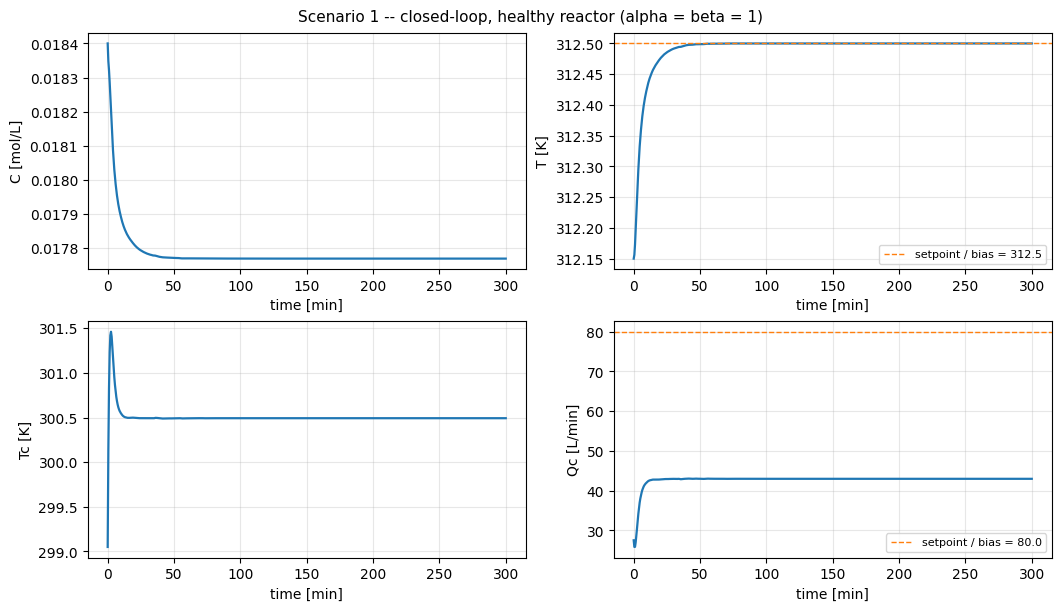

Final state at t = 300 min:
  C  = 0.01777 mol/L
  T  = 312.5000 K   (Tsp = 312.5,   |T - Tsp| = 0.0000)
  Tc = 300.4927 K
  I  = -2.469
  Qc = 42.976 L/min


In [13]:
t_cl, ys_cl, qc_cl = simulate_closed_loop_trajectory(
    NOMINAL_PARAMS_CL, NOMINAL_INLET_CL, NOMINAL_CTRL, NOMINAL_Y0_CL,
    t_final=300.0, n_save=601,
)
t_cl  = np.asarray(t_cl)
ys_cl = np.asarray(ys_cl)
qc_cl = np.asarray(qc_cl)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6), constrained_layout=True)
panel = [
    ("C [mol/L]",  ys_cl[:, 0], None),
    ("T [K]",      ys_cl[:, 1], TSP),
    ("Tc [K]",     ys_cl[:, 2], None),
    ("Qc [L/min]", qc_cl,        QC0),
]
for ax, (lab, y, ref) in zip(axes.ravel(), panel):
    ax.plot(t_cl, y, lw=1.6)
    if ref is not None:
        ax.axhline(ref, color="C1", ls="--", lw=1.0,
                   label=f"setpoint / bias = {ref}")
        ax.legend(loc="best", fontsize=8)
    ax.set_xlabel("time [min]")
    ax.set_ylabel(lab)
    ax.grid(alpha=0.3)
fig.suptitle(
    "Scenario 1 -- closed-loop, healthy reactor (alpha = beta = 1)",
    fontsize=11,
)
plt.show()

print("Final state at t = 300 min:")
print(f"  C  = {ys_cl[-1, 0]:.5f} mol/L")
print(f"  T  = {ys_cl[-1, 1]:.4f} K   (Tsp = {TSP},   |T - Tsp| = {abs(ys_cl[-1,1]-TSP):.4f})")
print(f"  Tc = {ys_cl[-1, 2]:.4f} K")
print(f"  I  = {ys_cl[-1, 3]:+.3f}")
print(f"  Qc = {qc_cl[-1]:.3f} L/min")

## 4. The headline phenomenon: jacket fouling vs catalyst decay

Three closed-loop runs share identical inlet conditions and identical
controller settings. Only the degradation factors differ:

| Scenario | $\alpha$ | $\beta$ | Failure mode |
|---:|:---:|:---:|:---|
| Sc 1 | 1.0  | 1.0  | healthy baseline                    |
| Sc 2 | 1.0  | 0.85 | jacket fouling (β·UA drops 15% → **UA_eff = 0.85·UA**) |
| Sc 3 | 0.7  | 1.0  | catalyst decay (α·k0 drops 30% → **k0_eff = 0.7·k0**) |

The temperature `T` looks *very similar* across the three because the
controller compensates -- exactly the masking effect that motivates
the closed-loop SBI study (research spec Section 1). The fault signal
lives in `Qc`: fouling pushes the valve more open (analytic steady state 43.1 → 109.9 L/min
for β = 1 → 0.85), decay pushes it slightly more closed (43.1 → 36.3 L/min for α = 0.7).
The two faults have qualitatively *different* signatures. The asymmetry has a physical
reason: at ~98% conversion the heat released barely depends on α, while β directly sets the
heat the jacket can remove.


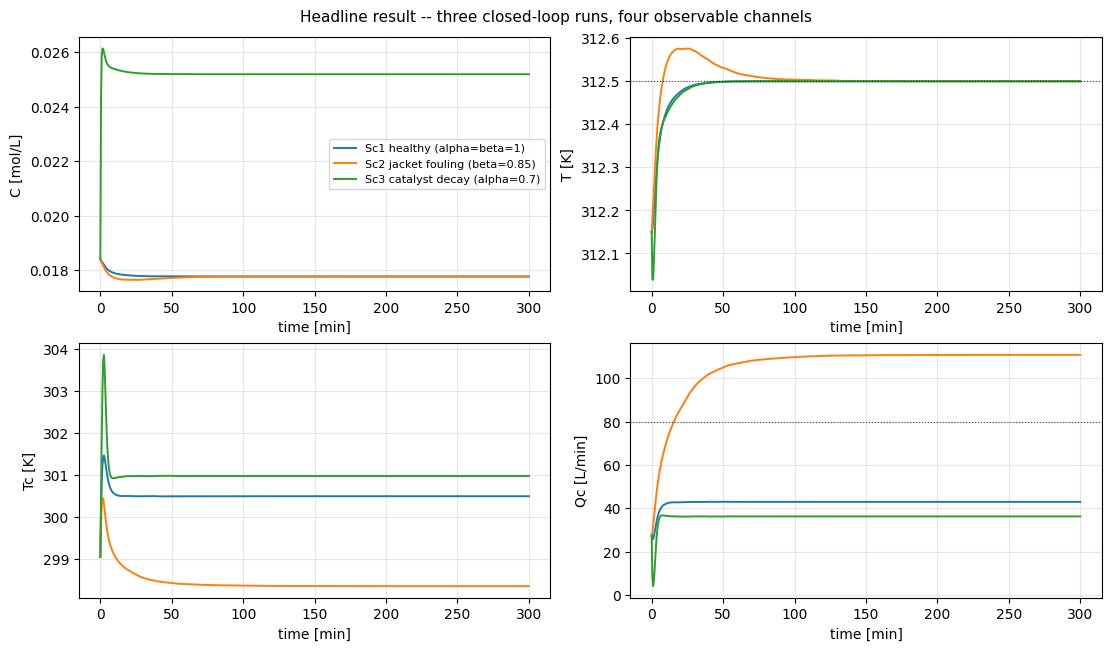

                      scenario      C_ss      T_ss     Tc_ss     Qc_ss
    Sc1 healthy (alpha=beta=1)    0.0178  312.5000  300.4927   42.9759
Sc2 jacket fouling (beta=0.85)    0.0178  312.5000  298.3572  110.7088
Sc3 catalyst decay (alpha=0.7)    0.0252  312.5000  300.9721   36.2758


In [14]:
def run_scenario(alpha, beta, label):
    params = jnp.array([UA_NOMINAL, K0_NOMINAL, alpha, beta])
    t, ys, qc = simulate_closed_loop_trajectory(
        params, NOMINAL_INLET_CL, NOMINAL_CTRL, NOMINAL_Y0_CL,
        t_final=300.0, n_save=601,
    )
    return label, np.asarray(t), np.asarray(ys), np.asarray(qc)

scenarios = [
    run_scenario(1.0, 1.0, "Sc1 healthy (alpha=beta=1)"),
    run_scenario(1.0, 0.85, "Sc2 jacket fouling (beta=0.85)"),
    run_scenario(0.7, 1.0, "Sc3 catalyst decay (alpha=0.7)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), constrained_layout=True)
labels = ["C [mol/L]", "T [K]", "Tc [K]", "Qc [L/min]"]
for label, t, ys, qc in scenarios:
    series = [ys[:, 0], ys[:, 1], ys[:, 2], qc]
    for ax, lab, y in zip(axes.ravel(), labels, series):
        ax.plot(t, y, lw=1.4, label=label)
        ax.set_xlabel("time [min]")
        ax.set_ylabel(lab)
        ax.grid(alpha=0.3)
axes[0, 1].axhline(TSP, color="k", ls=":", lw=0.8, alpha=0.7,
                   label=f"Tsp = {TSP}")
axes[1, 1].axhline(QC0, color="k", ls=":", lw=0.8, alpha=0.7,
                   label=f"Qc0 = {QC0}")
axes[0, 0].legend(loc="best", fontsize=8)
fig.suptitle(
    "Headline result -- three closed-loop runs, four observable channels",
    fontsize=11,
)
plt.show()

rows = []
for label, _, ys, qc in scenarios:
    rows.append({
        "scenario": label,
        "C_ss":  ys[-1, 0],
        "T_ss":  ys[-1, 1],
        "Tc_ss": ys[-1, 2],
        "Qc_ss": qc[-1],
    })
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:9.4f}"))

## 5. Controller saturation (Scenario 5)

When fouling becomes severe enough that the cooling demand exceeds
`Qc_max`, the proportional + integral output saturates and the
reactor temperature drifts above setpoint. In this design the jacket removes only ~19% of
the reaction heat (the cold feed absorbs ~81%), so the margin is small: the valve reaches
`Qc_max = 400 L/min` at β ≈ 0.795, and below β ≈ 0.775 no coolant flow could hold the
setpoint at all. The sweep below brackets that onset.

Two distinct identifiability challenges are present in this regime:

1. **Structural non-identifiability** (always present): UA and β only appear
   as the product β·UA in the ODE — they cannot be separated from observations
   alone. This is why the inference parameter is β (with UA fixed at its known
   clean-service value), not `[UA, β]` jointly.

2. **Saturation-induced identifiability loss**: when Qc is clamped at `Qc_max`,
   the Qc channel carries no additional information about β — a more severe
   fault (smaller β) would require an even larger Qc, but the valve is already
   fully open. The posterior on β widens dramatically in this regime.

The M6/M8 notebook (`08_identifiability_and_saturation`) will quantify the
β threshold at which Qc saturates and the SBI posterior begins to lose
resolution.


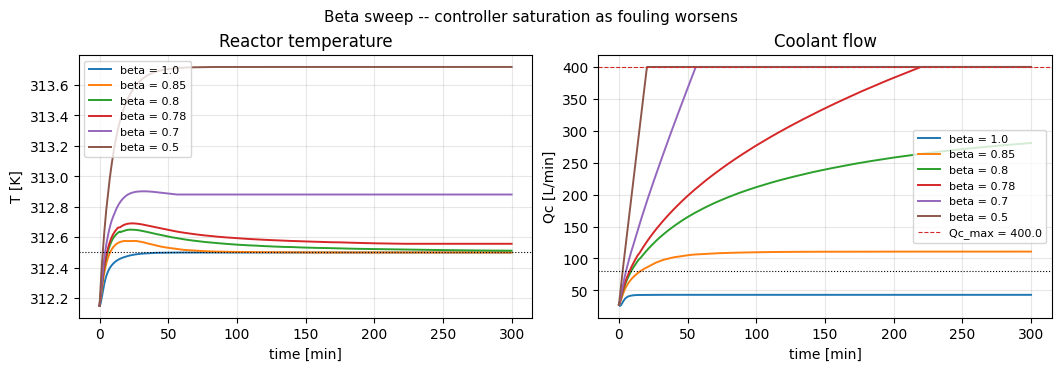

      beta   T_ss [K]  T_ss - Tsp [K]  Qc_ss [L/min] saturated
    1.0000   312.5000          0.0000        42.9759        no
    0.8500   312.5000          0.0000       110.7088        no
    0.8000   312.5117          0.0117       280.8179        no
    0.7800   312.5571          0.0571       400.0000       yes
    0.7000   312.8806          0.3806       400.0000       yes
    0.5000   313.7184          1.2184       400.0000       yes


In [15]:
sweep_betas = [1.0, 0.85, 0.80, 0.78, 0.70, 0.50]   # within the prior [0.4, 1.2]; onset at ~0.795
rows = []
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), constrained_layout=True)
for beta in sweep_betas:
    params = jnp.array([UA_NOMINAL, K0_NOMINAL, 1.0, beta])
    t, ys, qc = simulate_closed_loop_trajectory(
        params, NOMINAL_INLET_CL, NOMINAL_CTRL, NOMINAL_Y0_CL,
        t_final=300.0, n_save=601,
    )
    t  = np.asarray(t)
    ys = np.asarray(ys)
    qc = np.asarray(qc)
    axes[0].plot(t, ys[:, 1], lw=1.4, label=f"beta = {beta}")
    axes[1].plot(t, qc,        lw=1.4, label=f"beta = {beta}")
    rows.append({
        "beta":           beta,
        "T_ss [K]":       ys[-1, 1],
        "T_ss - Tsp [K]": ys[-1, 1] - TSP,
        "Qc_ss [L/min]":  qc[-1],
        "saturated":      "yes" if qc[-1] >= QC_MAX - 1e-3 else "no",
    })

axes[0].axhline(TSP, color="k", ls=":", lw=0.8)
axes[0].set_xlabel("time [min]"); axes[0].set_ylabel("T [K]")
axes[0].set_title("Reactor temperature")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].axhline(QC_MAX, color="C3", ls="--", lw=0.8, label=f"Qc_max = {QC_MAX}")
axes[1].axhline(QC0,    color="k",  ls=":",  lw=0.8)
axes[1].set_xlabel("time [min]"); axes[1].set_ylabel("Qc [L/min]")
axes[1].set_title("Coolant flow")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

fig.suptitle("Beta sweep -- controller saturation as fouling worsens", fontsize=11)
plt.show()

print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:10.4f}"))

## 6. M1 acceptance (2026-11-08, fixed controller law)

| Acceptance criterion | Expected (analytic steady state) |
|---|---|
| `cstr_closed_loop_rhs` returns a 4-state derivative | — |
| Sc 1 (α = β = 1) reaches `T → Tsp` | \|T − Tsp\| → 0 within ~50 min; Qc → 43.1 L/min |
| Sc 2 (β = 0.85) — `Qc` increases | Qc → 109.9 L/min, T at setpoint |
| Sc 3 (α = 0.7) — `Qc` decreases | Qc → 36.3 L/min, T at setpoint |
| β sweep — saturation onset | unsaturated at β ≥ 0.80 (Qc ≈ 310 L/min at 0.80); saturated at β ≤ 0.78, T above setpoint |
| Anti-windup keeps the integrator finite under saturation | `I` stays bounded in the saturated runs |

Compare the printed final states with this table after re-running; a mismatch means the
simulator and the analytic steady state disagree and must be investigated.

M1 is complete. M2 (`src/cstr_sbi/simulator.py`, notebook 02) adds process noise during
integration, sensor noise and drift, and the 60-minute observation window.

> **Note on convergence speed (corrected 2026-11-08).** An earlier version of this note said
> that with τi = 10 min the residual |T − Tsp| closes "very slowly" and called this a property
> of the tuning. It was a coding error in the PI law (integral term without Kp, 150× too
> weak). With the standard form the slowest closed-loop time constant is 10–26 min across the
> operating range, so a 60-min observation window spans 2–6 time constants.